# **Project 30:** *Analyzis of Wordnet consistency in Synonymy and Antonymy relationships*
**Authors:**
* Miro Lammi
* Eemeli Kyröläinen (2309218), ekyrolai23@student.oulu.fi

#### Requirements (*Python 3.12*):
`pip install nltk` <br>
`pip install pandas` <br>
`pip install jupyter` <br>
`pip install matplotlib` <br>
`pip install numpy` <br>

or run: <br>
`pip install -r requirements.txt`

## Imports and initialization

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.patches import Patch
from matplotlib.legend_handler import HandlerTuple
from collections import defaultdict
from itertools import combinations

from nltk.corpus import wordnet as wn

POS_TAGS = [wn.NOUN, wn.VERB]
METHODS = ["path", "wup"]
COLORS = {
    ("synonym", wn.NOUN): "#4682B4",
    ("synonym", wn.VERB): "#8DB9D8",
    ("antonym", wn.NOUN): "#DC143C",
    ("antonym", wn.VERB): "#F08080",
}


def similarity(s1, s2, method="path"):
    if method not in METHODS:
        raise ValueError("[ERROR]: Invalid method! method must be one of {}".format(METHODS))
    if method == "path":
        return wn.synset(s1).path_similarity(wn.synset(s2))
    return wn.synset(s1).wup_similarity(wn.synset(s2))

## 1. Getting synonyms and antonyms for each verb and noun in WordNet lexical database and calculating path similarity for each pair.

In [34]:
def get_all_pairs(pos):
    pairs = set()

    for synset in wn.all_synsets(pos):
        lemmas = synset.lemmas()

        for l1, l2 in combinations(lemmas, 2):
            w1, w2 = sorted([l1.name(), l2.name()])

            if w1 != w2:
                pairs.add((pos, "synonym", w1, w2, synset.name(), synset.name()))

        for lemma in lemmas:
            for antonym in lemma.antonyms():
                a_synset = antonym.synset()
                if a_synset.pos() != pos:
                    continue

                a, b = sorted([(lemma.name(), synset.name()),
                               (antonym.name(), a_synset.name())])

                if a[0] != b[0]:
                    pairs.add((pos, "antonym", a[0], b[0], a[1], b[1]))
    return pairs

results = []

for pos in POS_TAGS:
    pairs = get_all_pairs(pos)

    for p, rel, w1, w2, s1, s2 in pairs:
        sim = similarity(s1, s2, "wup")
        results.append({
            'pos': p,
            'relation': rel,
            'word1': w1,
            'word2': w2,
            's1': s1,
            's2': s2,
            'similarity': sim
        })

DATAFRAME = pd.DataFrame(results)

statistics = (DATAFRAME.groupby(["pos", "relation"])["similarity"].agg(["count", "min", "max", "mean"]))
display(statistics)

count       min       max      mean
pos relation                                      
n   antonym     1076  0.125000  0.933333  0.752211
    synonym   107469  0.727273  1.000000  0.996726
v   antonym      548  0.111111  0.857143  0.367114
    synonym    24577  0.666667  1.000000  0.999938

[Interpretation of results]

 ## 2. Generate pair similarity distribution histograms

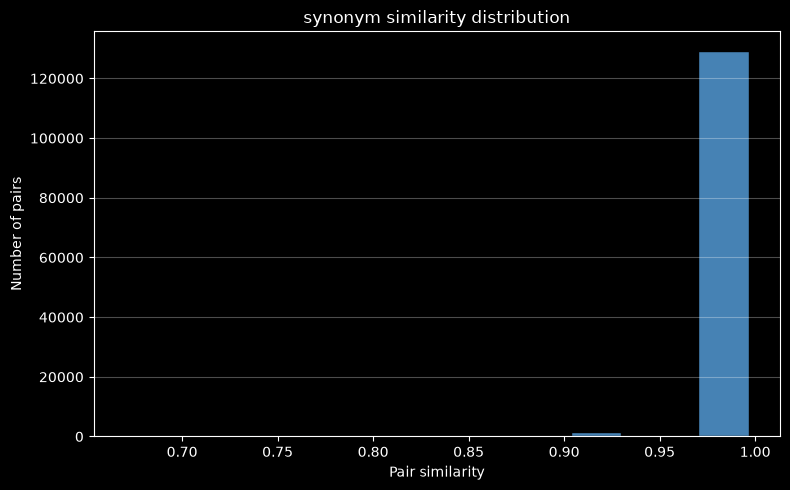

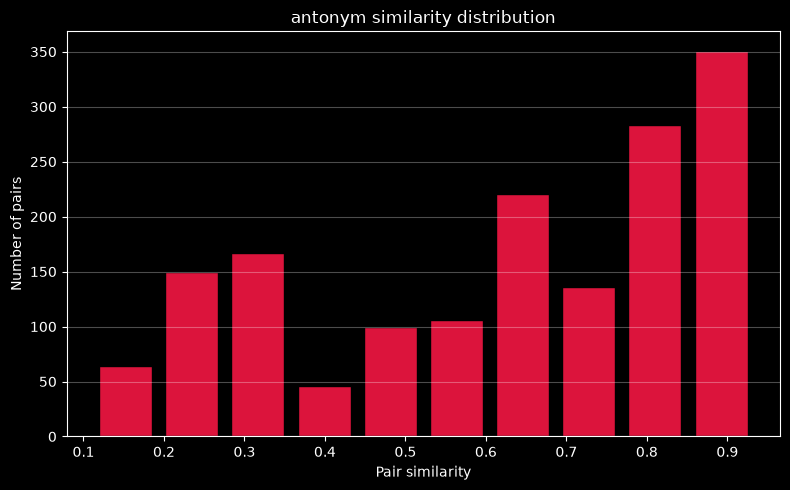

In [35]:
BIN_COUNT = 10

for relation in ["synonym", "antonym"]:
    sims = DATAFRAME.loc[DATAFRAME["relation"] == relation, "similarity"].dropna()

    min_sim = sims.min()
    max_sim = sims.max()

    bins = np.linspace(min_sim, max_sim, BIN_COUNT + 1)

    plt.figure(figsize=(8,5))
    plt.hist(sims, bins=bins, edgecolor="black", rwidth=0.8, color=COLORS[relation, "n"])
    plt.xlabel("Pair similarity")
    plt.ylabel("Number of pairs")
    plt.title(f"{relation} similarity distribution")
    plt.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.show()
    print()

[Interpretation of results]

 ## 3. Difference between semantic similarity can be used distinguish between synonymy and antonymy
"Validating your answer using statistical hypothesis testing"

In [36]:
# Reserved for possible code for 3.
pass

## 4. Transitivity relationships in synonyms and antonyms

,pos,relation,total,successful,percentage
0,n,synonym,367083,257613,70.178407
1,n,antonym,67,20,29.850746
2,v,synonym,233414,110223,47.222103
3,v,antonym,91,21,23.076923


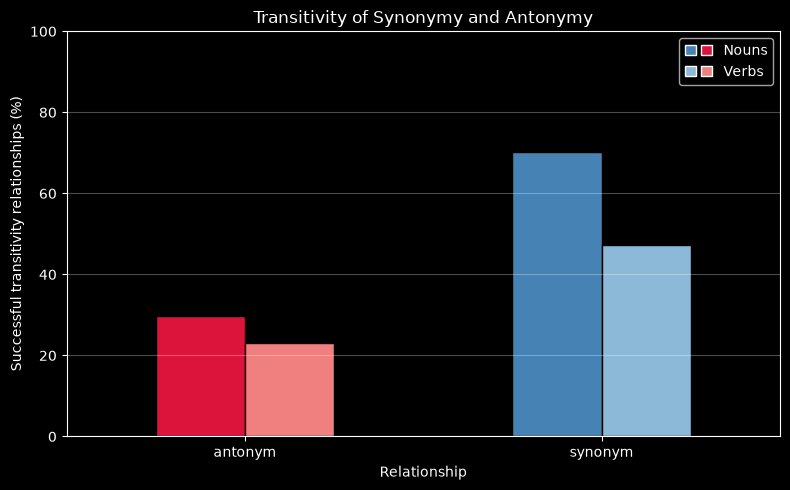

In [37]:
def build_relations_tables(df_pos):
    synonyms = defaultdict(set)
    antonyms = defaultdict(set)

    for row in df_pos.itertuples(index=False):
        table = synonyms if row.relation == "synonym" else antonyms
        table[row.word1].add(row.word2)
        table[row.word2].add(row.word1)

    return synonyms, antonyms


def get_transitivity_relationships(relations, synonyms):
    count = 0
    success = 0

    for y, neighbor in relations.items():
        for x, z in combinations(neighbor, 2):
            count += 1
            if z in synonyms.get(x, set()):
                success += 1

    return count, success


results = []

for pos in POS_TAGS:
    df_pos = DATAFRAME[DATAFRAME["pos"] == pos]

    synonyms, antonyms = build_relations_tables(df_pos)

    for relation, relations in [("synonym", synonyms), ("antonym", antonyms)]:
        total, successful = get_transitivity_relationships(relations, synonyms)

        results.append({
            'pos': pos,
            'relation': relation,
            'total': total,
            'successful': successful,
            'percentage': (successful / total) * 100 if total > 0 else 0
        })

df_transitivity = pd.DataFrame(results)
display(df_transitivity)

pivot = df_transitivity.pivot(
    index="relation",
    columns="pos",
    values="percentage"
)

ax = pivot.plot.bar(figsize=(8,5), edgecolor="black", rot=0)
for container, pos in zip(ax.containers, pivot.columns):
    for bar, relation in zip(container, pivot.index):
        bar.set_facecolor(COLORS[(relation, pos)])

ax.set_title("Transitivity of Synonymy and Antonymy")
ax.set_xlabel("Relationship")
ax.set_ylabel("Successful transitivity relationships (%)")
ax.set_ylim(0, 100)
ax.legend(["Nouns", "Verbs"])
legend_handles = [
    (
        Patch(facecolor=COLORS[('synonym', 'n')], edgecolor="white"),
        Patch(facecolor=COLORS[('antonym', 'n')], edgecolor="white")
    ),
    (
        Patch(facecolor=COLORS[('synonym', 'v')], edgecolor="white"),
        Patch(facecolor=COLORS[('antonym', 'v')], edgecolor="white")
    )
]

ax.legend(
    legend_handles,
    ["Nouns", "Verbs"],
    handler_map={tuple: HandlerTuple(ndivide=None)}
)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

[Interpretation of results]

## 5. Hypernymy in synonyms

,pos,total,shared hypernym count,percentage
0,Noun,105032,92926,88.473989
1,Verb,23020,21646,94.031277


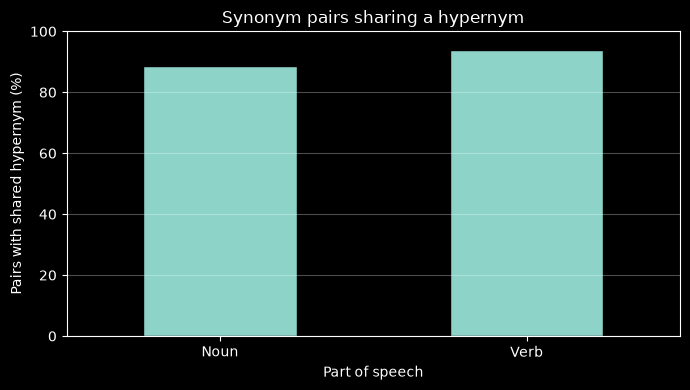

In [38]:
def has_common_hypernym(word1, word2, pos):
    for s1 in wn.synsets(word1, pos=pos):
        for s2 in wn.synsets(word2, pos=pos):
            if set(s1.hypernyms()) & set(s2.hypernyms()):
                return True
    return False


results = []

for pos in POS_TAGS:
    df_synonyms = DATAFRAME[
        (DATAFRAME["pos"] == pos) &
        (DATAFRAME["relation"] == "synonym")
    ]

    df_synonyms = df_synonyms.drop_duplicates(subset=["word1", "word2"])
    total = len(df_synonyms)

    hypernym_count = sum(
        has_common_hypernym(row.word1, row.word2, pos) for row in df_synonyms.itertuples(index=False)
    )

    results.append({
        'pos': "Noun" if pos == wn.NOUN else "Verb",
        'total': total,
        'shared hypernym count': hypernym_count,
        'percentage': (hypernym_count / total) * 100 if total > 0 else 0
    })

df_hypernyms_syn = pd.DataFrame(results)
display(df_hypernyms_syn)

ax = df_hypernyms_syn.plot.bar(
    x="pos",
    y="percentage",
    figsize=(7, 4),
    legend=False,
    edgecolor="black",
    rot=0
)

ax.set_title("Synonym pairs sharing a hypernym")
ax.set_xlabel("Part of speech")
ax.set_ylabel("Pairs with shared hypernym (%)")
ax.set_ylim(0, 100)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

[Interpretation of results]

## 6. Hypernymy in antonyms

,pos,total,shared hypernym count,percentage
0,Noun,992,597,60.181452
1,Verb,476,164,34.453782


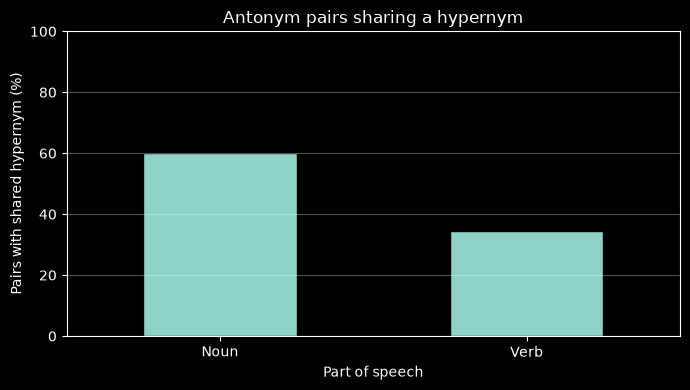

In [39]:
results = []

for pos in POS_TAGS:
    df_antonyms = DATAFRAME[
        (DATAFRAME["pos"] == pos) &
        (DATAFRAME["relation"] == "antonym")
    ]

    df_antonyms = df_antonyms.drop_duplicates(subset=["word1", "word2"])
    total = len(df_antonyms)

    hypernym_count = sum(
        has_common_hypernym(row.word1, row.word2, pos) for row in df_antonyms.itertuples(index=False)
    )

    results.append({
        'pos': "Noun" if pos == wn.NOUN else "Verb",
        'total': total,
        'shared hypernym count': hypernym_count,
        'percentage': (hypernym_count / total) * 100 if total > 0 else 0
    })

df_hypernyms_ant = pd.DataFrame(results)
display(df_hypernyms_ant)

ax = df_hypernyms_ant.plot.bar(
    x="pos",
    y="percentage",
    figsize=(7, 4),
    legend=False,
    edgecolor="black",
    rot=0
)

ax.set_title("Antonym pairs sharing a hypernym")
ax.set_xlabel("Part of speech")
ax.set_ylabel("Pairs with shared hypernym (%)")
ax.set_ylim(0, 100)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

[Interpretation of results]

## 7. Word2Vec maximum and minimum distance